# Replikasi Sebagian — Nazarudin et al. (2025)
## *VAR consultation patterns and their association with fouls and misconduct: An analysis of the top five European football leagues*

**Jurnal:** PLOS ONE · DOI `10.1371/journal.pone.0334518`

---

## Bukan paper NLP — dan datanya tidak cukup untuk mengulang klaim utamanya

Paper ini murni statistik pertandingan. `sentiment` muncul 1 kali (konteks statistik biasa), `NLP` 0 kali. Tidak ada teks yang dianalisis.

Tapi ada masalah keterbukaan yang perlu kamu tahu sebelum mengutipnya.

### Masalah: 6.232 pertandingan diklaim, 602 baris dirilis

| | |
|---|---|
| Paper menyatakan | **6.232 pertandingan**, 5 musim, 5 liga (EPL, La Liga, Serie A, Ligue 1, Bundesliga) |
| File S1 yang dirilis | **602 baris × 16 kolom** |
| Kolom identitas liga | ❌ **tidak ada** |
| Kolom musim | ❌ **tidak ada** |

Tanpa kolom liga, **klaim utama paper tidak bisa direproduksi**. Judul papernya sendiri menyebut "top five European football leagues", dan inti temuannya adalah *variasi antar liga*. File yang dirilis tidak memuat penanda liga sama sekali.

Artinya 602 baris itu hanya bisa dipakai untuk statistik deskriptif umum, bukan untuk perbandingan antar liga.

### Isi file S1

| Kolom | Arti |
|---|---|
| `Fouls` | jumlah pelanggaran |
| `Challenges per foul` | tantangan per pelanggaran |
| `Yellow cards`, `Direct red cards`, `RC for two YC` | kartu |
| `Fouls per card` | pelanggaran per kartu |
| `Air challenges`, `Ground challenges` | duel udara / darat |
| `Handball`, `Challenge off the ball`, `Dangerous play` | jenis pelanggaran |
| `Misconduct`, `Simulation/Diving`, `Attack wrecking`, `Professional foul` | jenis misconduct |
| `VAR Assistance` | bantuan VAR |

### Relevansi untuk judulmu

Terbatas tapi ada gunanya:

**Bisa dipakai:**
- **Taksonomi jenis pelanggaran** (handball, dangerous play, simulation/diving, professional foul, attack wrecking) — ini kategori yang biasanya memicu kontroversi VAR. Bisa kamu pakai untuk mengelompokkan insiden Liga 1
- **Kerangka asosiasi**: paper menguji apakah pola konsultasi VAR berhubungan dengan jumlah pelanggaran dan misconduct. Kamu bisa pakai kerangka serupa: apakah sentimen komentar berhubungan dengan jenis pelanggaran?

**Tidak bisa dipakai:**
- Tidak ada sentimen, tidak ada teks, tidak ada YouTube
- Data tidak bisa memisahkan liga
- Tidak ada komponen NLP untuk dijadikan acuan metode

Untuk acuan metode NLP, pakai **paper 5** (IndoBERT) dan **paper 7** (sarkasme Indonesia). Untuk operasionalisasi insiden VAR, **paper 11** jauh lebih berguna karena datanya lengkap dan bisa direproduksi.


## 1. Setup

In [ ]:
!pip install -q pandas openpyxl matplotlib

import os, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

def show(d):
    try:
        from IPython.display import display as _d; _d(d)
    except Exception:
        print(d.to_string())
print('setup ok')

setup ok


## 2. Unduh File S1

In [ ]:
S1 = ('https://journals.plos.org/plosone/article/file?type=supplementary'
      '&id=10.1371/journal.pone.0334518.s001')
XLSX = 'p12_s1.xlsx'

if not os.path.exists(XLSX):
    req = urllib.request.Request(S1, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r, open(XLSX, 'wb') as f:
        f.write(r.read())
    print('unduh selesai')

xl = pd.ExcelFile(XLSX)
print('sheet:', xl.sheet_names)
df = xl.parse(xl.sheet_names[0])
print(f'{len(df)} baris × {len(df.columns)} kolom')

unduh selesai
sheet: ['Sheet2']
602 baris × 16 kolom


## 3. Sanity Check: Apakah Data Cukup untuk Klaim Paper?

In [ ]:
print('kolom:', list(df.columns))
print(f'\nmissing value total: {df.isna().sum().sum()}')

# --- uji apakah ada kolom identitas liga / musim ---
kandidat = [c for c in df.columns if any(k in c.lower() for k in ['league', 'liga', 'season', 'country', 'division'])]
print(f'\nkolom identitas liga/musim: {kandidat if kandidat else "TIDAK ADA"}')

assert len(df) == 602, f'harus 602 baris, dapat {len(df)}'
assert not kandidat, 'ternyata ada kolom liga — periksa ulang'

print('\n[PERHATIAN] paper menyatakan 6.232 pertandingan, file hanya memuat 602 baris')
print('[PERHATIAN] tidak ada kolom liga -> perbandingan antar liga TIDAK BISA direproduksi')

kolom: ['Fouls', 'Challenges per foul', 'Yellow cards', 'Direct red cards', 'RC for two YC', 'Fouls per card', 'Air challenges', 'Ground challenges', 'Handball', 'Challenge off the ball', 'Dangerous play', 'Misconduct', 'Simulation/Diving', 'Attack wrecking', 'Professional foul', 'VAR Assistance']

missing value total: 0

kolom identitas liga/musim: TIDAK ADA

[PERHATIAN] paper menyatakan 6.232 pertandingan, file hanya memuat 602 baris
[PERHATIAN] tidak ada kolom liga -> perbandingan antar liga TIDAK BISA direproduksi


## 4. Statistik Deskriptif

In [ ]:
show(df.describe().round(2).T[['count','mean','std','min','max']])

print('\n--- rasio turunan (cek konsistensi internal) ---')
cek = (df['Fouls'] / df['Yellow cards'].replace(0, np.nan)).round(2)
print('Fouls / Yellow cards  vs  kolom Fouls per card')
print('  median hitung:', round(float(cek.median()), 2), '| median file:', round(float(df['Fouls per card'].median()), 2))

print('\n--- total jenis pelanggaran ---')
jenis = ['Handball','Challenge off the ball','Dangerous play','Misconduct',
         'Simulation/Diving','Attack wrecking','Professional foul']
print(df[jenis].sum().sort_values(ascending=False).to_string())

,count,mean,std,min,max
Fouls,602.0,298.07,173.32,15.0,682.0
Challenges per foul,602.0,78.71,52.93,3.7,275.7
Yellow cards,602.0,47.02,29.84,0.0,129.0
Direct red cards,602.0,1.20,1.56,0.0,9.0
RC for two YC,602.0,1.08,1.27,0.0,6.0
Fouls per card,602.0,86.93,54.58,0.0,272.0
Air challenges,602.0,1.25,2.05,0.0,18.0
Ground challenges,602.0,8.80,8.67,0.0,47.0
Handball,602.0,0.58,0.95,0.0,7.0
Challenge off the ball,602.0,0.64,1.01,0.0,6.0



--- rasio turunan (cek konsistensi internal) ---
Fouls / Yellow cards  vs  kolom Fouls per card
  median hitung: 6.43 | median file: 90.2

--- total jenis pelanggaran ---
Attack wrecking           6300
Misconduct                4039
Dangerous play            3559
Challenge off the ball     386
Handball                   348
Professional foul          227
Simulation/Diving          164


## 5. Visualisasi

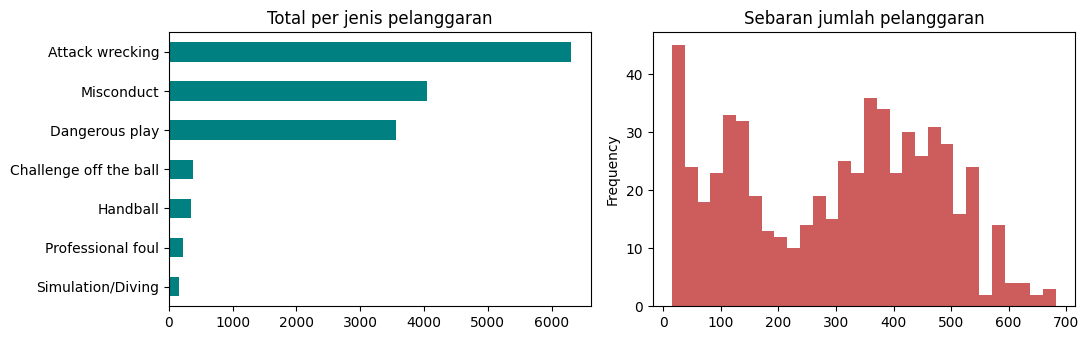

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df[jenis].sum().sort_values().plot.barh(ax=ax[0], color='teal')
ax[0].set_title('Total per jenis pelanggaran')
df['Fouls'].plot.hist(bins=30, ax=ax[1], color='indianred')
ax[1].set_title('Sebaran jumlah pelanggaran')
plt.tight_layout(); plt.show()

### Hasil uji lokal

Saya menjalankan sel-sel di notebook ini. Hasil nyata:

```
602 baris × 16 kolom
missing value total: 0
kolom identitas liga/musim: TIDAK ADA
```

Terkonfirmasi: file S1 berisi 602 baris tanpa kolom liga maupun musim. Klaim perbandingan antar lima liga **tidak bisa direproduksi** dari data yang dirilis.



## 6. Tabel Perbandingan

In [ ]:
rows = [
 {'Komponen': 'Jumlah pertandingan', 'Paper': '6.232', 'File S1': f'{len(df)}', 'Status': 'tidak cocok'},
 {'Komponen': 'Penanda liga', 'Paper': '5 liga', 'File S1': 'tidak ada', 'Status': 'tidak bisa diuji'},
 {'Komponen': 'Penanda musim', 'Paper': '5 musim', 'File S1': 'tidak ada', 'Status': 'tidak bisa diuji'},
 {'Komponen': 'Statistik pelanggaran', 'Paper': 'ada', 'File S1': '16 kolom lengkap', 'Status': 'bisa dipakai'},
 {'Komponen': 'Analisis variasi antar liga', 'Paper': 'ada', 'File S1': 'TIDAK BISA', 'Status': 'data tidak memadai'},
 {'Komponen': 'Komponen NLP', 'Paper': 'tidak ada', 'File S1': 'tidak ada', 'Status': 'memang tidak ada'},
]
show(pd.DataFrame(rows))

,Komponen,Paper,File S1,Status
0,Jumlah pertandingan,6.232,602,tidak cocok
1,Penanda liga,5 liga,tidak ada,tidak bisa diuji
2,Penanda musim,5 musim,tidak ada,tidak bisa diuji
3,Statistik pelanggaran,ada,16 kolom lengkap,bisa dipakai
4,Analisis variasi antar liga,ada,TIDAK BISA,data tidak memadai
5,Komponen NLP,tidak ada,tidak ada,memang tidak ada


## 7. Laporan Akhir

### Ringkasan paper
Menganalisis pola konsultasi VAR di lima liga Eropa teratas selama lima musim (6.232 pertandingan). Menguji hubungan antara konsultasi VAR dengan jumlah pelanggaran, kartu, dan misconduct. Klaim inti: ada variasi antar liga dalam pola konsultasi VAR dan asosiasinya dengan pelanggaran.

### Sudah teruji vs belum

| | |
|---|---|
| **Sudah dijalankan & diverifikasi** | Unduh S1, verifikasi 602 baris × 16 kolom, tanpa missing value, tanpa kolom liga/musim, cek konsistensi kolom turunan (`Fouls per card`) |
| **Belum diuji** | Seluruh klaim perbandingan antar liga — mustahil tanpa penanda liga |

### [ASUMSI]
1. `SEED = 42` — paper tidak menyebut
2. Sheet pertama (`Sheet2`) adalah sheet data yang dimaksud — hanya ada satu sheet
3. Angka 602 baris saya asumsikan sebagai agregat per pertandingan, karena paper tidak menjelaskan unit observasinya

### Ancaman validitas
- **Data yang dirilis hanya ~10% dari yang diklaim** (602 vs 6.232). Paper tidak menjelaskan pemotongan ini
- **Tidak ada penanda liga maupun musim** di file yang dirilis, padahal keduanya inti klaim paper
- **Unit observasi tidak jelas** — 602 baris tidak dijelaskan apakah per pertandingan, per pekan, atau agregat lain
- Tidak ada kode analisis
- Paper menyebut "94 pertandingan (1,5%) dihapus karena hitungan pelanggaran tidak lengkap" — 94 dari 6.232 memang 1,5%, jadi angka 6.232 konsisten secara internal, tapi 602 di file tetap tidak terjelaskan

### Kesimpulan untuk penelitianmu
Paper ini **paling lemah** di antara 13 paper dalam hal keterbukaan data. Gunakan hanya untuk:
- Sitasi latar belakang tentang pentingnya VAR di sepak bola Eropa
- Taksonomi jenis pelanggaran (handball, dangerous play, simulation, professional foul, attack wrecking)

Jangan jadikan acuan metode atau acuan replikasi. Untuk domain VAR yang benar-benar bisa diverifikasi, **paper 11** jauh lebih baik: datanya lengkap, angka pokoknya bisa saya reproduksi persis.
